In [8]:
# First, install the missing package
!pip install mlxtend

%matplotlib inline

#Módulos de manipulación de datos
import pandas as pd
import numpy as np

#Módulos de scikit-learn de machine learning
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import LinearSVC, SVC

#Módulos de evaluación de modelos
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, RocCurveDisplay, PrecisionRecallDisplay

#Librerías de visualización
from mlxtend.plotting import plot_decision_regions  # This will work after installing mlxtend
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
plt.style.use('ggplot')

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd

ruta_df1 = r"C:\Users\carte\OneDrive\Documentos\MASTER IA\MACHINE LEARNING\PRACTICA\df1.csv"
ruta_df2 = r"C:\Users\carte\OneDrive\Documentos\MASTER IA\MACHINE LEARNING\PRACTICA\df2.csv"
ruta_df3 = r"C:\Users\carte\OneDrive\Documentos\MASTER IA\MACHINE LEARNING\PRACTICA\df3.csv"

# Cargar los CSV
df1 = pd.read_csv(ruta_df1)
df2 = pd.read_csv(ruta_df2)
df3 = pd.read_csv(ruta_df3)

# Verificar que se han cargado correctamente
print(df1.head())
print(df2.head())
print(df3.head())

         X1         X2  y
0  1.851247  -6.732371  1
1 -1.205689  -6.293264  0
2  0.169261 -13.061934  0
3 -0.389015  -0.491930  1
4  4.947719  -1.705707  1
         X1        X2  y
0  0.584252  0.823704  0
1 -0.358890  0.157146  1
2 -0.108836 -0.304280  1
3 -1.029144 -0.534329  0
4  0.326033 -0.584400  1
         X1        X2  y
0  0.508607  0.793824  0
1  1.030402 -0.476137  1
2  1.674906 -0.076727  1
3 -0.559781  0.961497  0
4  1.946447 -0.219177  1


In [ ]:
df1.head()

In [28]:
datasets = [df1, df2, df3]
datasets_names = ['df1', 'df2', 'df3']

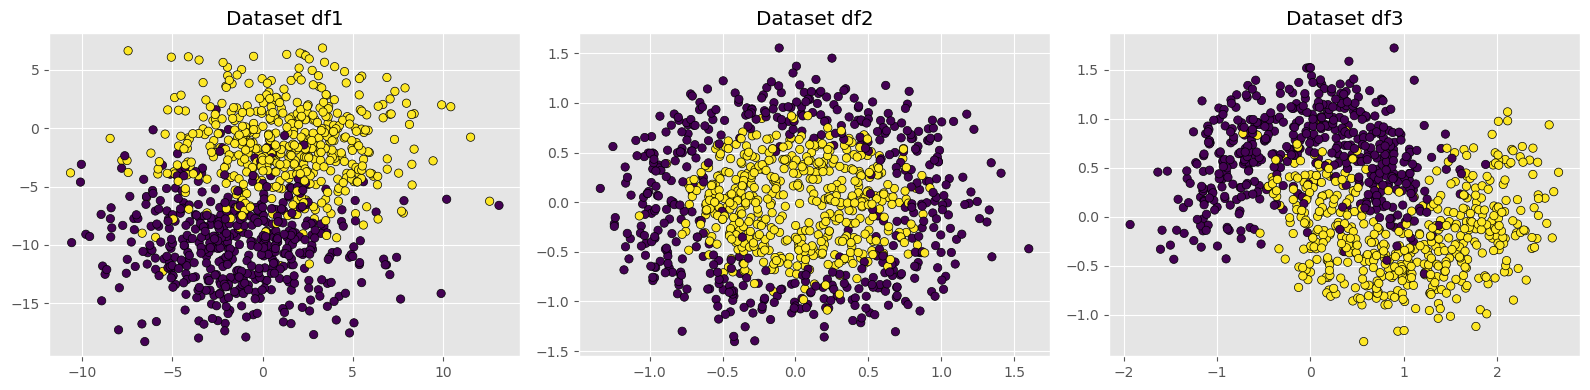

In [14]:
import matplotlib.pyplot as plt

# (Recomendado en Jupyter)
%matplotlib inline

datasets = [df1, df2, df3]
datasets_names = ['df1', 'df2', 'df3']

f, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, df, name in zip(axes, datasets, datasets_names):
    ax.scatter(df['X1'], df['X2'], c=df['y'], edgecolors='k')
    ax.set_title('Dataset ' + name)

plt.tight_layout()
plt.show()

# KNN

In [25]:
datasets_train = []
datasets_test = []

for df in datasets:
    df_train, df_test = train_test_split(df,test_size=0.2,
                                         stratify=df['y'], 
                                         random_state=1993)   
    datasets_train.append(df_train)
    datasets_test.append(df_test)

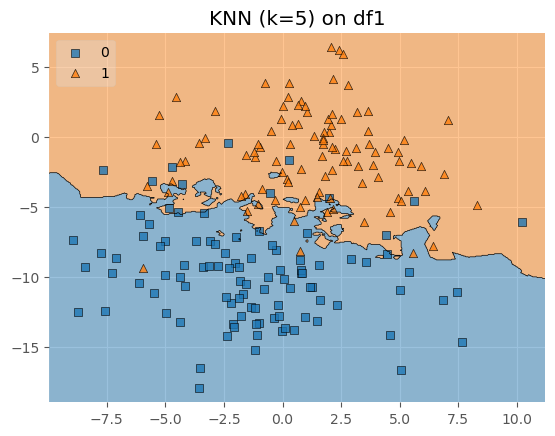

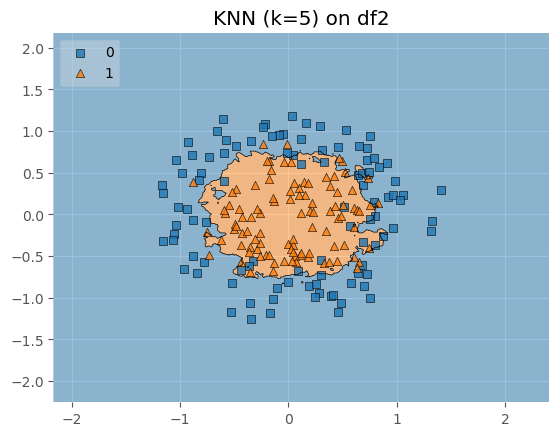

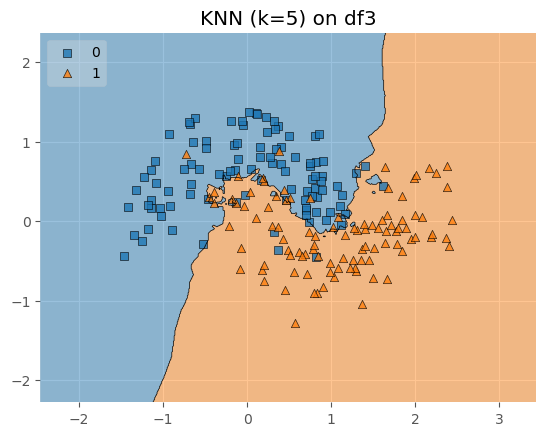

In [26]:
knn_models = []

for df_train, df_test, name in zip(datasets_train, datasets_test, datasets_names):
    
    knn = KNeighborsClassifier(n_neighbors=5)  # puedes probar 3, 7, 9...
    knn.fit(df_train[['X1', 'X2']], df_train['y'])
    
    plot_decision_regions(df_test[['X1', 'X2']].values,
                          df_test['y'].values,
                          clf=knn,
                          legend=2)
    plt.title('KNN (k=5) on ' + name)
    plt.show()
    
    knn_models.append(knn)

############################################## 
Classification Report for df1
############################################## 

Matriz de confusión: 



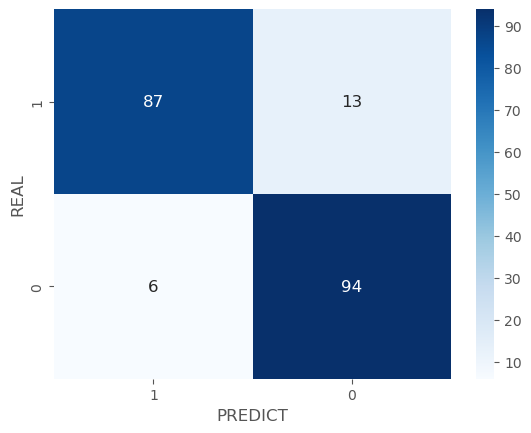

Accuracy:  0.905
Precision: 0.879
Recall:    0.94
Fscore:    0.908




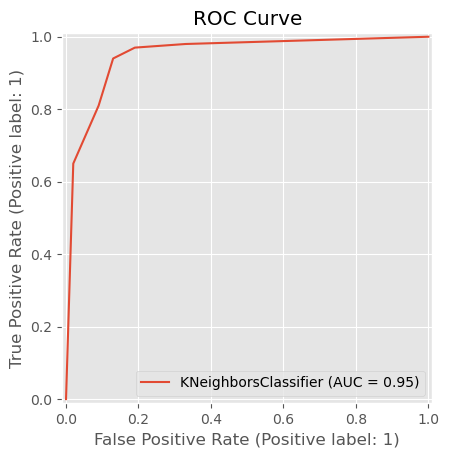

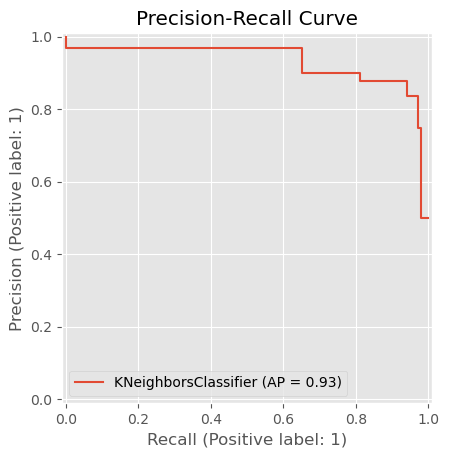

############################################## 
Classification Report for df2
############################################## 

Matriz de confusión: 



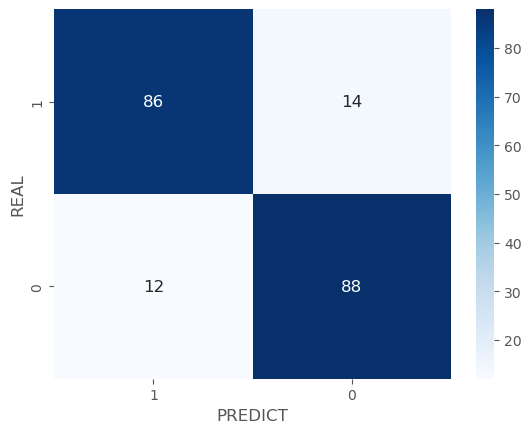

Accuracy:  0.87
Precision: 0.863
Recall:    0.88
Fscore:    0.871




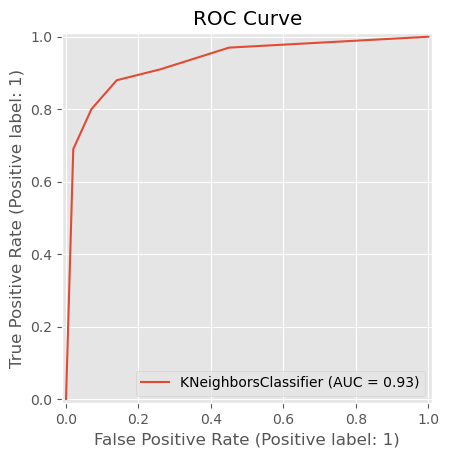

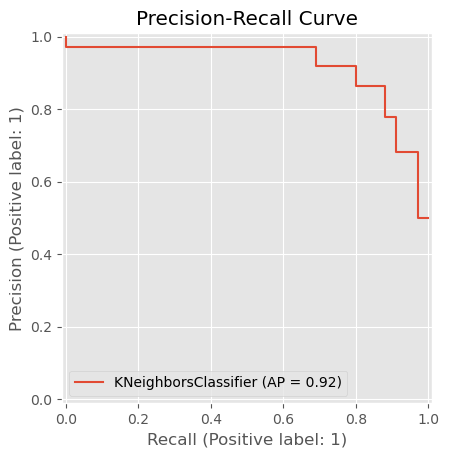

############################################## 
Classification Report for df3
############################################## 

Matriz de confusión: 



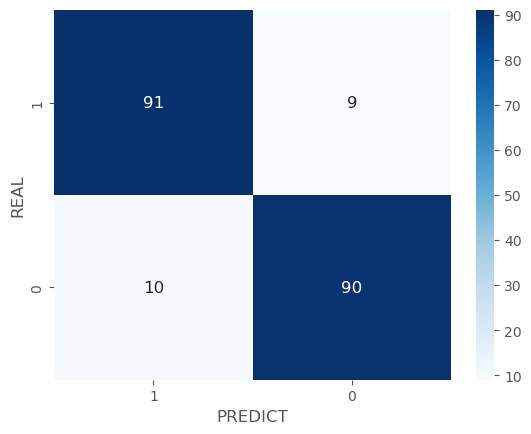

Accuracy:  0.905
Precision: 0.909
Recall:    0.9
Fscore:    0.905




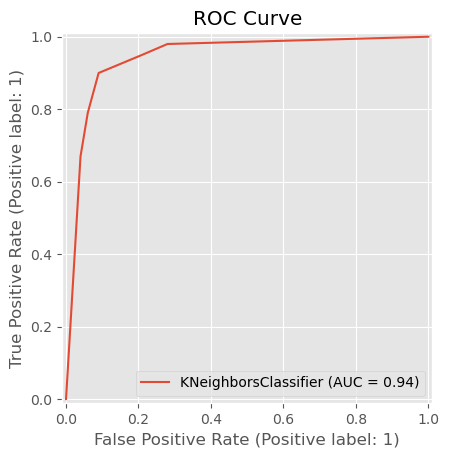

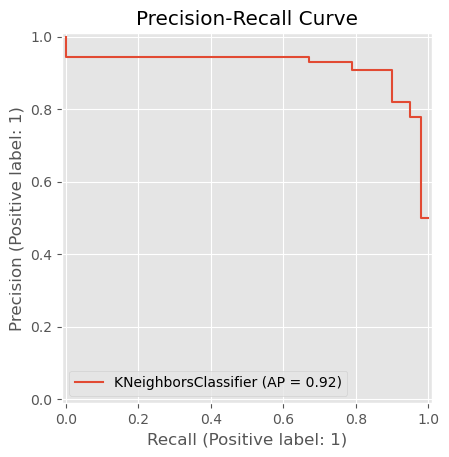

In [27]:
for knn, df_test, name in zip(knn_models, datasets_test, datasets_names):
    
    print('############################################## ')
    print('Classification Report for ' + name)
    print('############################################## \n')

    # Predicción
    df_test['y_knn'] = knn.predict(df_test[['X1', 'X2']])

    # Matriz de confusión
    print('Matriz de confusión: \n')
    conf_mat = confusion_matrix(df_test['y'], df_test['y_knn'])
    sns.heatmap(conf_mat, annot=True, xticklabels=[1, 0], yticklabels=[1, 0],
                cmap='Blues', annot_kws={"fontsize":12})
    plt.xlabel('PREDICT')
    plt.ylabel('REAL')
    plt.show()

    # Métricas
    print("Accuracy: ", accuracy_score(df_test['y'], df_test['y_knn']))
    print('Precision:', round(precision_score(df_test['y'], df_test['y_knn']), 3))
    print('Recall:   ', round(recall_score(df_test['y'], df_test['y_knn']), 3))
    print('Fscore:   ', round(f1_score(df_test['y'], df_test['y_knn']), 3))
    print('\n')

    # Curva ROC
    RocCurveDisplay.from_estimator(knn, df_test[['X1', 'X2']], df_test['y'])
    plt.title('ROC Curve')
    plt.show()

    # Curva Precision-Recall
    PrecisionRecallDisplay.from_estimator(knn, df_test[['X1', 'X2']], df_test['y'])
    plt.title('Precision-Recall Curve')
    plt.show()

# SVM

## KERNEL LINEAL

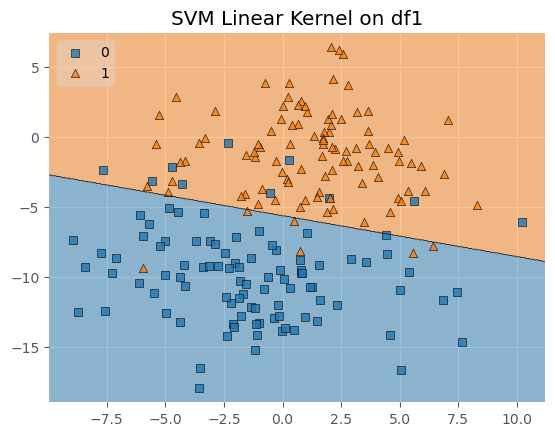

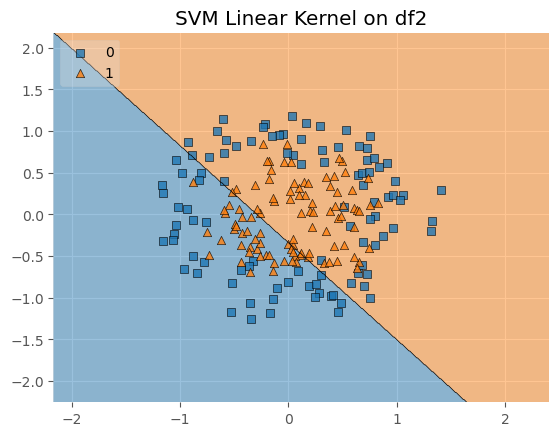

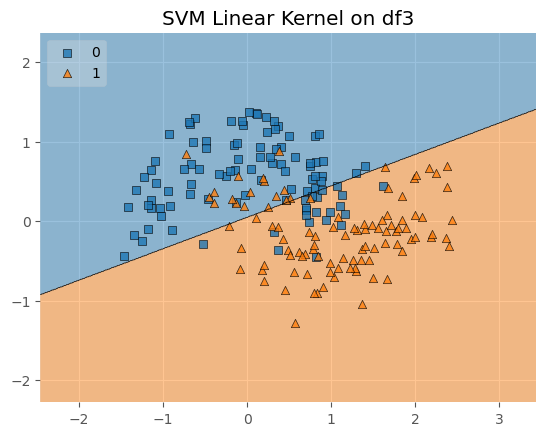

In [29]:
from sklearn.svm import SVC
import matplotlib.pyplot as plt

svm_linear_models = []

for df_train, df_test, name in zip(datasets_train, datasets_test, datasets_names):

    X_train = df_train[['X1', 'X2']].to_numpy()
    y_train = df_train['y'].to_numpy()

    X_test  = df_test[['X1', 'X2']].to_numpy()
    y_test  = df_test['y'].to_numpy()

    svm_linear = SVC(kernel='linear', C=1, probability=True)
    svm_linear.fit(X_train, y_train)

    plot_decision_regions(X_test, y_test, clf=svm_linear, legend=2)
    plt.title('SVM Linear Kernel on ' + name)
    plt.show()

    svm_linear_models.append(svm_linear)

############################################## 
Classification Report for df1
############################################## 

Matriz de confusión: 



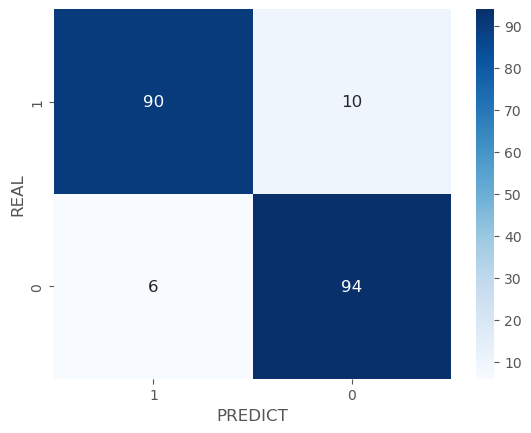

Accuracy:  0.92
Precision: 0.904
Recall:    0.94
Fscore:    0.922




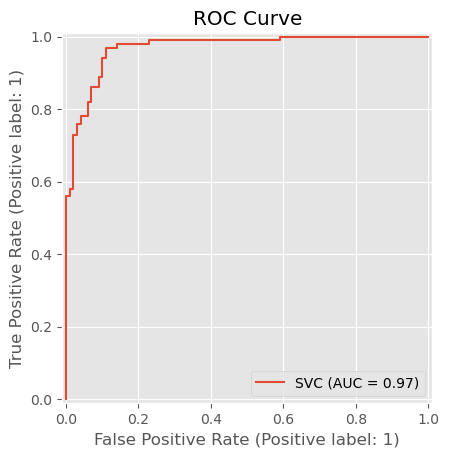

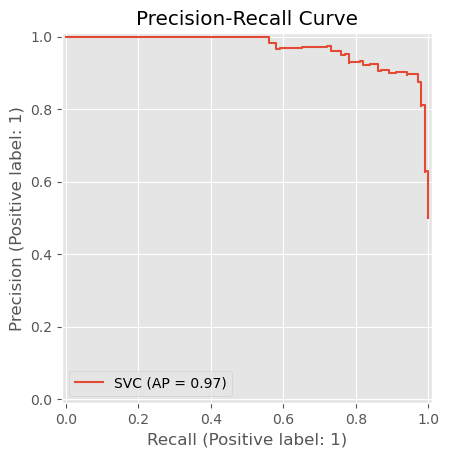

############################################## 
Classification Report for df2
############################################## 

Matriz de confusión: 



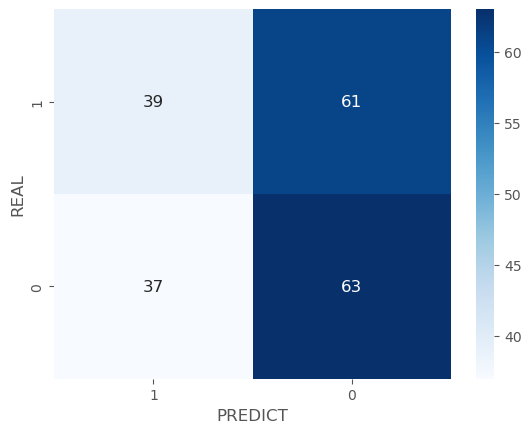

Accuracy:  0.51
Precision: 0.508
Recall:    0.63
Fscore:    0.562




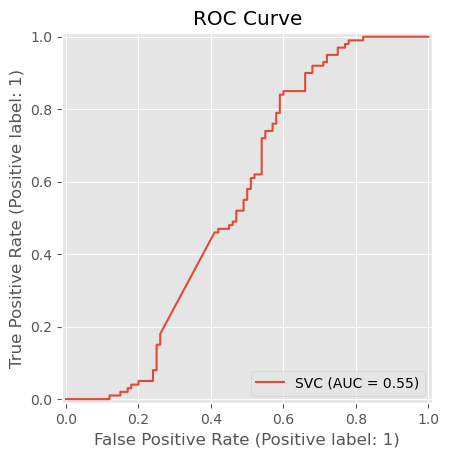

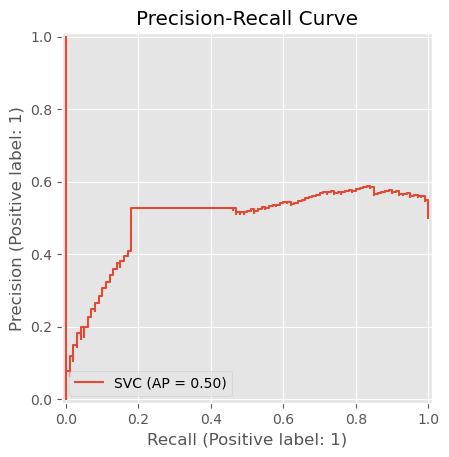

############################################## 
Classification Report for df3
############################################## 

Matriz de confusión: 



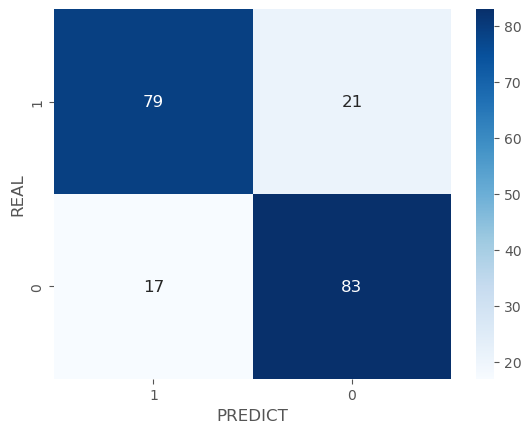

Accuracy:  0.81
Precision: 0.798
Recall:    0.83
Fscore:    0.814




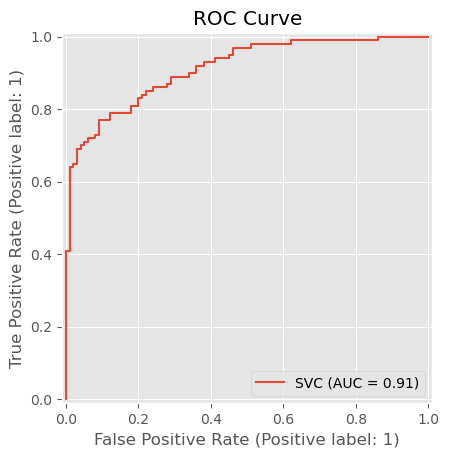

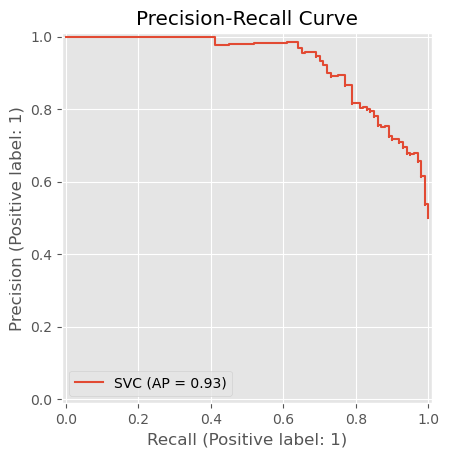

In [30]:
for svm_linear, df_test, name in zip(svm_linear_models, datasets_test, datasets_names):

    print('############################################## ')
    print('Classification Report for ' + name)
    print('############################################## \n')

    X_test = df_test[['X1', 'X2']].to_numpy()
    y_test = df_test['y'].to_numpy()

    df_test['y_svm_linear'] = svm_linear.predict(X_test)

    # Matriz de confusión
    print('Matriz de confusión: \n')
    conf_mat = confusion_matrix(y_test, df_test['y_svm_linear'])
    sns.heatmap(conf_mat, annot=True, xticklabels=[1, 0], yticklabels=[1, 0],
                cmap='Blues', annot_kws={"fontsize":12})
    plt.xlabel('PREDICT')
    plt.ylabel('REAL')
    plt.show()

    # Métricas
    print("Accuracy: ", accuracy_score(y_test, df_test['y_svm_linear']))
    print('Precision:', round(precision_score(y_test, df_test['y_svm_linear']), 3))
    print('Recall:   ', round(recall_score(y_test, df_test['y_svm_linear']), 3))
    print('Fscore:   ', round(f1_score(y_test, df_test['y_svm_linear']), 3))
    print('\n')

    # Curva ROC
    RocCurveDisplay.from_estimator(svm_linear, X_test, y_test)
    plt.title('ROC Curve')
    plt.show()

    # Curva Precision-Recall
    PrecisionRecallDisplay.from_estimator(svm_linear, X_test, y_test)
    plt.title('Precision-Recall Curve')
    plt.show()

## KERNEL RADIAL

In [31]:
SVC(kernel='rbf')

SVC()

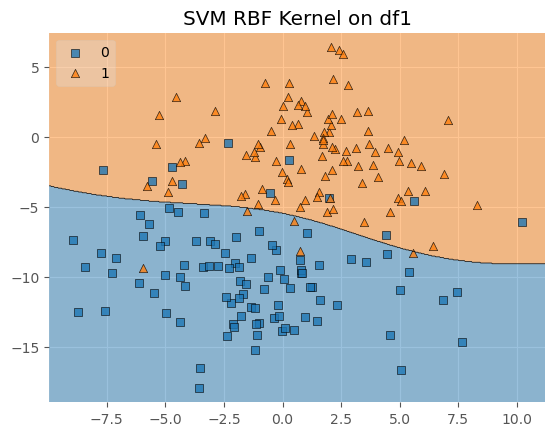

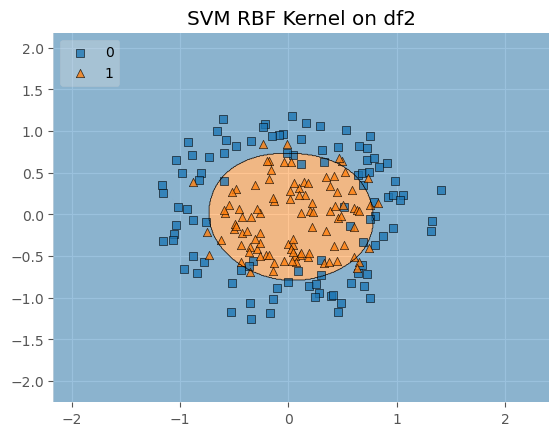

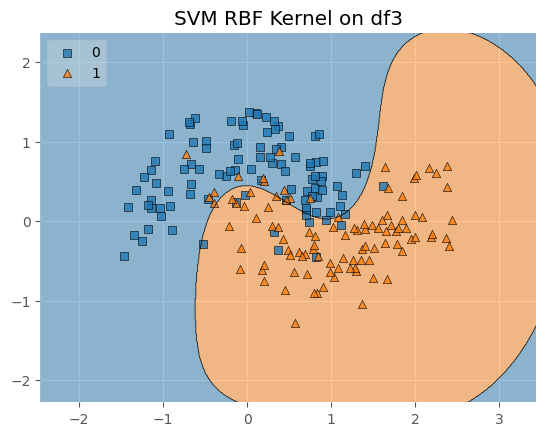

In [32]:
from sklearn.svm import SVC
import matplotlib.pyplot as plt

svm_rbf_models = []

for df_train, df_test, name in zip(datasets_train, datasets_test, datasets_names):

    X_train = df_train[['X1', 'X2']].to_numpy()
    y_train = df_train['y'].to_numpy()

    X_test  = df_test[['X1', 'X2']].to_numpy()
    y_test  = df_test['y'].to_numpy()

    svm_rbf = SVC(kernel='rbf', C=1, gamma='scale', probability=True)
    svm_rbf.fit(X_train, y_train)

    plot_decision_regions(X_test, y_test, clf=svm_rbf, legend=2)
    plt.title('SVM RBF Kernel on ' + name)
    plt.show()

    svm_rbf_models.append(svm_rbf)

############################################## 
Classification Report for df1
############################################## 

Matriz de confusión: 



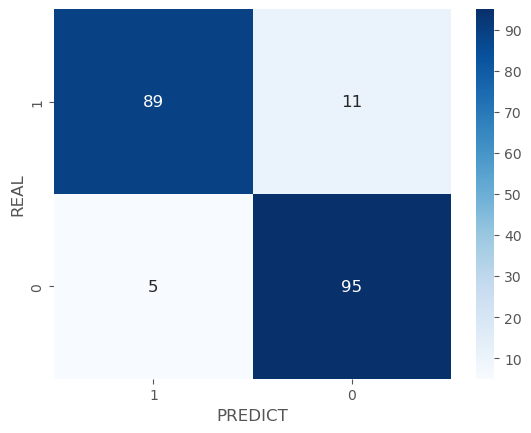

Accuracy:  0.92
Precision: 0.896
Recall:    0.95
Fscore:    0.922




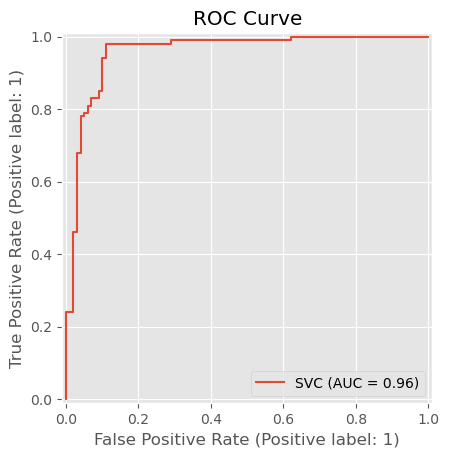

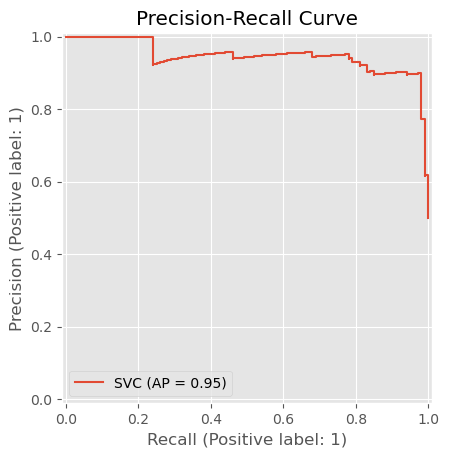

############################################## 
Classification Report for df2
############################################## 

Matriz de confusión: 



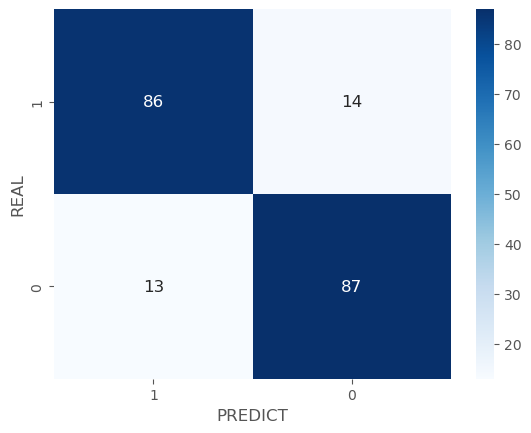

Accuracy:  0.865
Precision: 0.861
Recall:    0.87
Fscore:    0.866




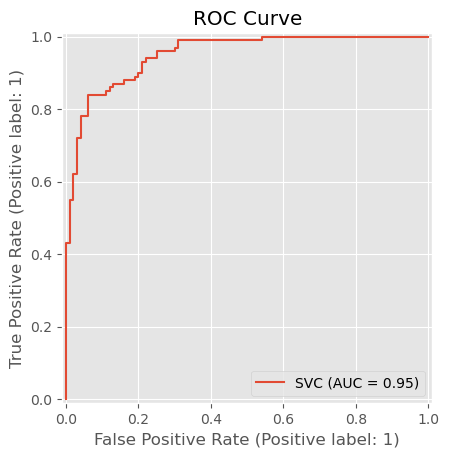

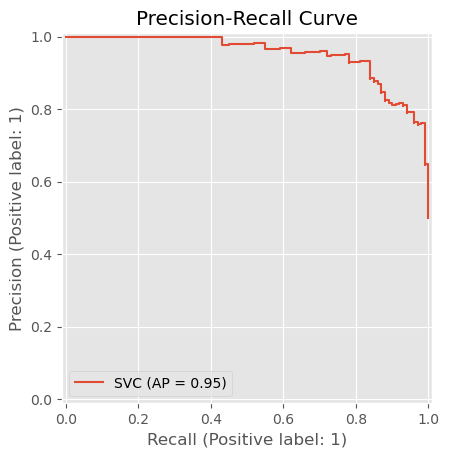

############################################## 
Classification Report for df3
############################################## 

Matriz de confusión: 



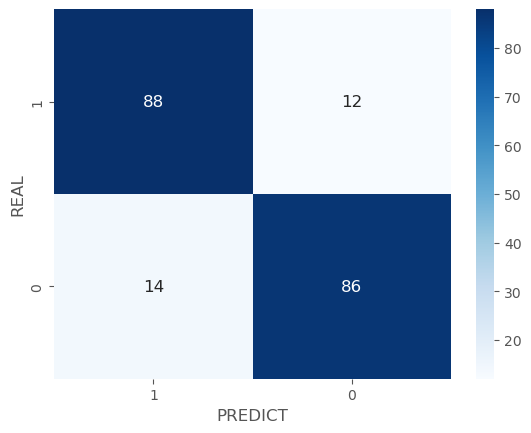

Accuracy:  0.87
Precision: 0.878
Recall:    0.86
Fscore:    0.869




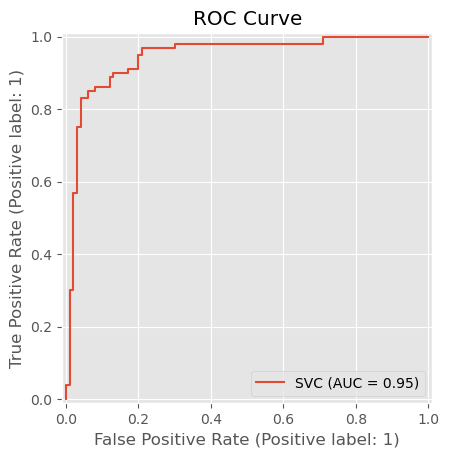

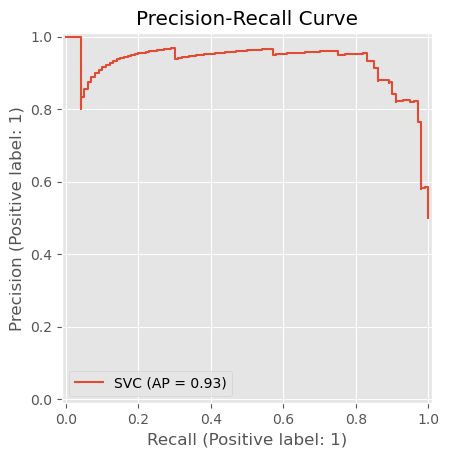

In [33]:
for svm_rbf, df_test, name in zip(svm_rbf_models, datasets_test, datasets_names):

    print('############################################## ')
    print('Classification Report for ' + name)
    print('############################################## \n')

    X_test = df_test[['X1', 'X2']].to_numpy()
    y_test = df_test['y'].to_numpy()

    df_test['y_svm_rbf'] = svm_rbf.predict(X_test)

    # Matriz de confusión
    print('Matriz de confusión: \n')
    conf_mat = confusion_matrix(y_test, df_test['y_svm_rbf'])
    sns.heatmap(conf_mat, annot=True, xticklabels=[1, 0], yticklabels=[1, 0],
                cmap='Blues', annot_kws={"fontsize":12})
    plt.xlabel('PREDICT')
    plt.ylabel('REAL')
    plt.show()

    # Métricas
    print("Accuracy: ", accuracy_score(y_test, df_test['y_svm_rbf']))
    print('Precision:', round(precision_score(y_test, df_test['y_svm_rbf']), 3))
    print('Recall:   ', round(recall_score(y_test, df_test['y_svm_rbf']), 3))
    print('Fscore:   ', round(f1_score(y_test, df_test['y_svm_rbf']), 3))
    print('\n')

    # Curva ROC
    RocCurveDisplay.from_estimator(svm_rbf, X_test, y_test)
    plt.title('ROC Curve')
    plt.show()

    # Curva Precision-Recall
    PrecisionRecallDisplay.from_estimator(svm_rbf, X_test, y_test)
    plt.title('Precision-Recall Curve')
    plt.show()

# ARBOL DE DECISION

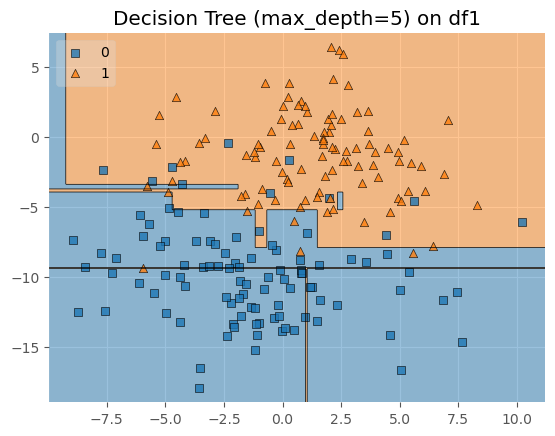

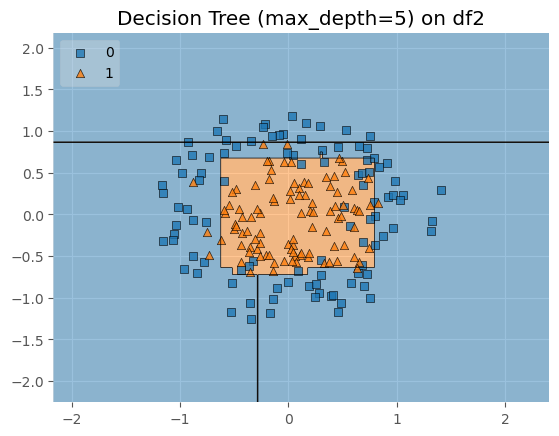

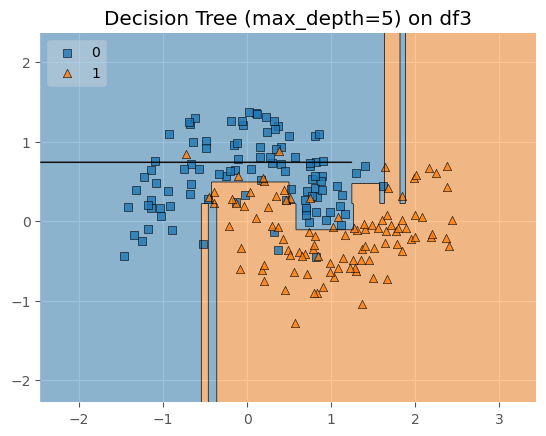

In [34]:
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt

dt_models = []

for df_train, df_test, name in zip(datasets_train, datasets_test, datasets_names):

    X_train = df_train[['X1', 'X2']].to_numpy()
    y_train = df_train['y'].to_numpy()

    X_test  = df_test[['X1', 'X2']].to_numpy()
    y_test  = df_test['y'].to_numpy()

    dt = DecisionTreeClassifier(max_depth=5, random_state=42)
    dt.fit(X_train, y_train)

    plot_decision_regions(X_test, y_test, clf=dt, legend=2)
    plt.title('Decision Tree (max_depth=5) on ' + name)
    plt.show()

    dt_models.append(dt)

############################################## 
Classification Report for df1
############################################## 

Matriz de confusión: 



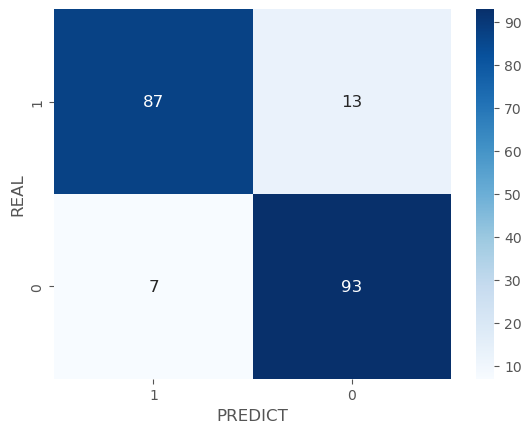

Accuracy:  0.9
Precision: 0.877
Recall:    0.93
Fscore:    0.903




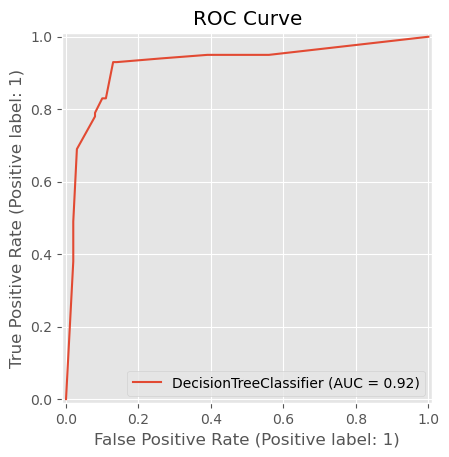

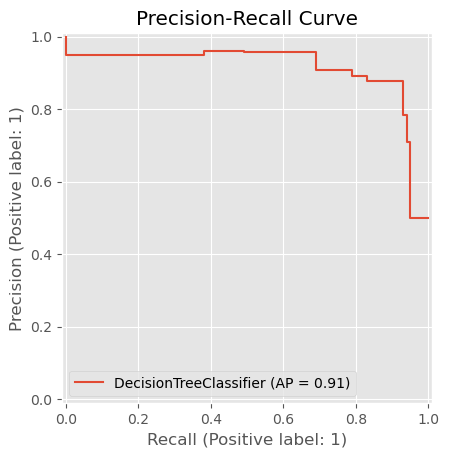

############################################## 
Classification Report for df2
############################################## 

Matriz de confusión: 



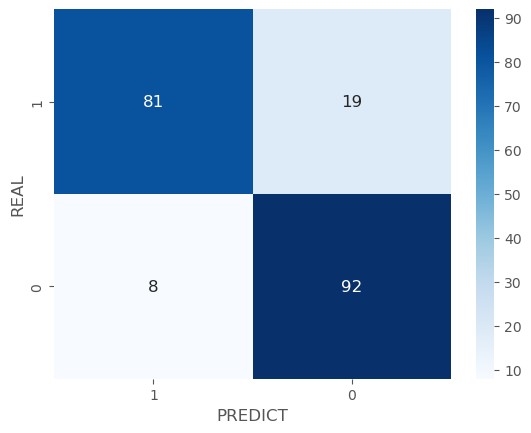

Accuracy:  0.865
Precision: 0.829
Recall:    0.92
Fscore:    0.872




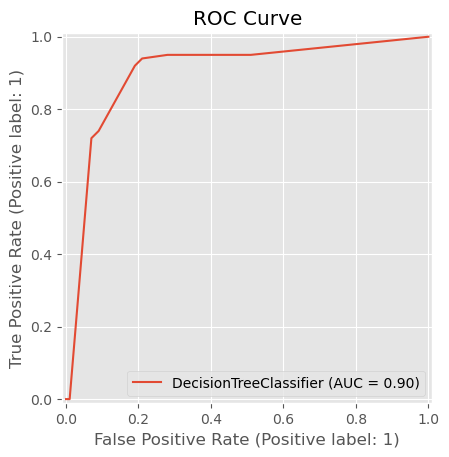

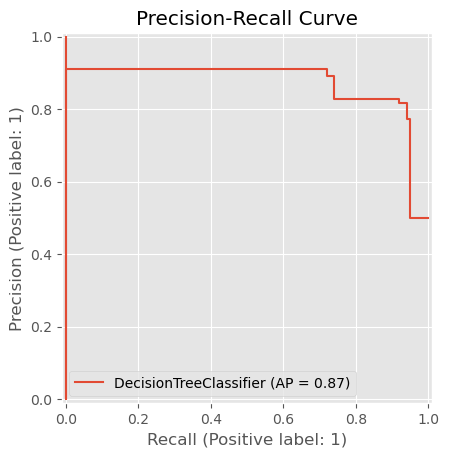

############################################## 
Classification Report for df3
############################################## 

Matriz de confusión: 



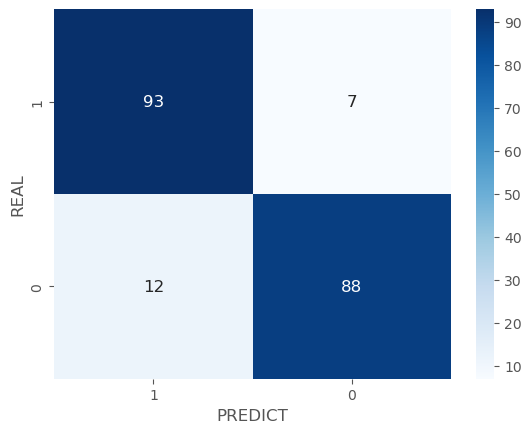

Accuracy:  0.905
Precision: 0.926
Recall:    0.88
Fscore:    0.903




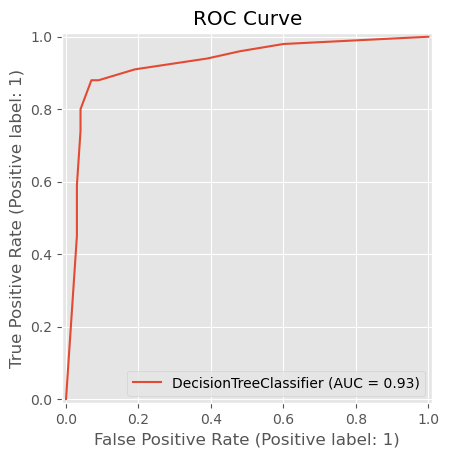

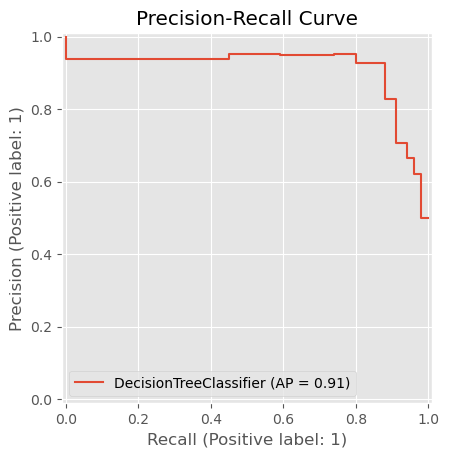

In [35]:
for dt, df_test, name in zip(dt_models, datasets_test, datasets_names):

    print('############################################## ')
    print('Classification Report for ' + name)
    print('############################################## \n')

    X_test = df_test[['X1', 'X2']].to_numpy()
    y_test = df_test['y'].to_numpy()

    df_test['y_dt'] = dt.predict(X_test)

    # Matriz de confusión
    print('Matriz de confusión: \n')
    conf_mat = confusion_matrix(y_test, df_test['y_dt'])
    sns.heatmap(conf_mat, annot=True, xticklabels=[1, 0], yticklabels=[1, 0],
                cmap='Blues', annot_kws={"fontsize":12})
    plt.xlabel('PREDICT')
    plt.ylabel('REAL')
    plt.show()

    # Métricas
    print("Accuracy: ", accuracy_score(y_test, df_test['y_dt']))
    print('Precision:', round(precision_score(y_test, df_test['y_dt']), 3))
    print('Recall:   ', round(recall_score(y_test, df_test['y_dt']), 3))
    print('Fscore:   ', round(f1_score(y_test, df_test['y_dt']), 3))
    print('\n')

    # Curva ROC
    RocCurveDisplay.from_estimator(dt, X_test, y_test)
    plt.title('ROC Curve')
    plt.show()

    # Curva Precision-Recall
    PrecisionRecallDisplay.from_estimator(dt, X_test, y_test)
    plt.title('Precision-Recall Curve')
    plt.show()

# RANDOM FOREST

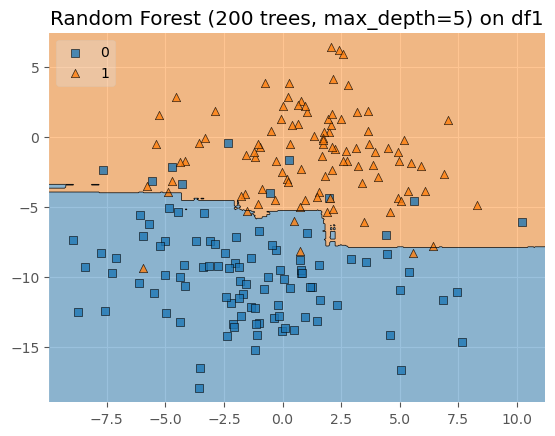

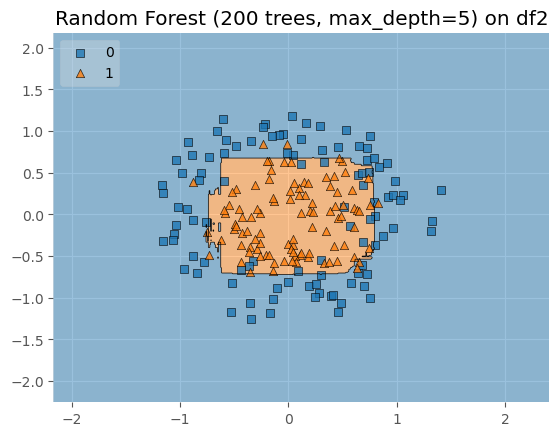

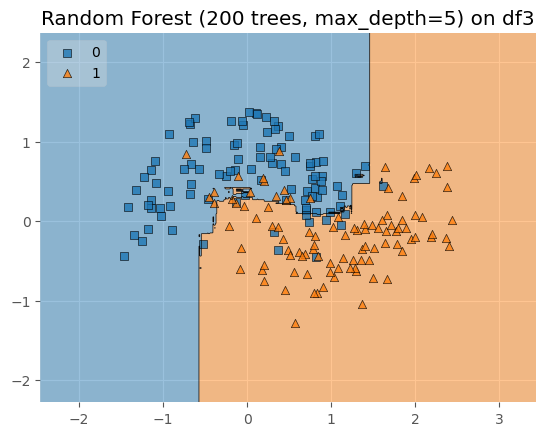

In [36]:
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

rf_models = []

for df_train, df_test, name in zip(datasets_train, datasets_test, datasets_names):

    X_train = df_train[['X1', 'X2']].to_numpy()
    y_train = df_train['y'].to_numpy()

    X_test  = df_test[['X1', 'X2']].to_numpy()
    y_test  = df_test['y'].to_numpy()

    rf = RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        random_state=42
    )
    rf.fit(X_train, y_train)

    plot_decision_regions(X_test, y_test, clf=rf, legend=2)
    plt.title('Random Forest (200 trees, max_depth=5) on ' + name)
    plt.show()

    rf_models.append(rf)

############################################## 
Classification Report for df1
############################################## 

Matriz de confusión: 



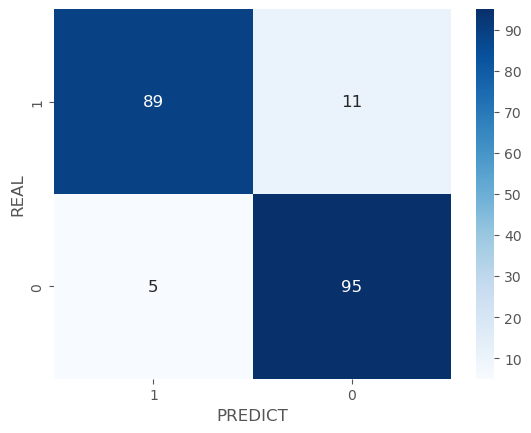

Accuracy:  0.92
Precision: 0.896
Recall:    0.95
Fscore:    0.922




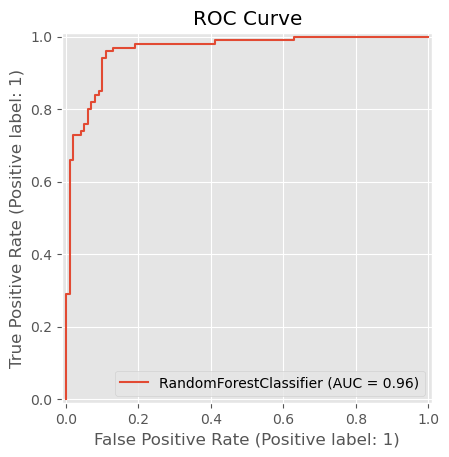

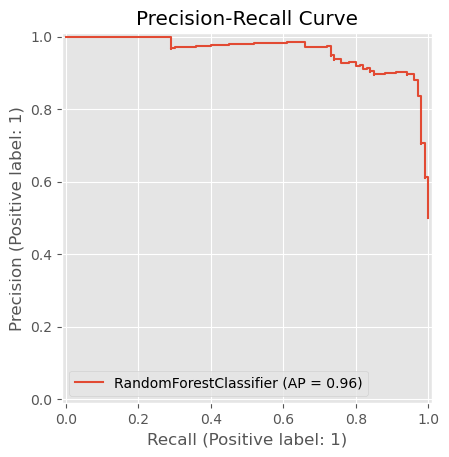

############################################## 
Classification Report for df2
############################################## 

Matriz de confusión: 



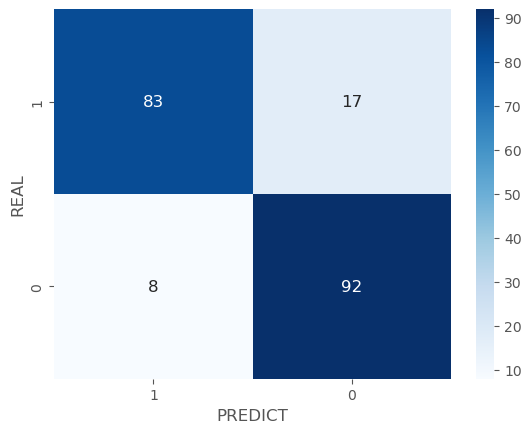

Accuracy:  0.875
Precision: 0.844
Recall:    0.92
Fscore:    0.88




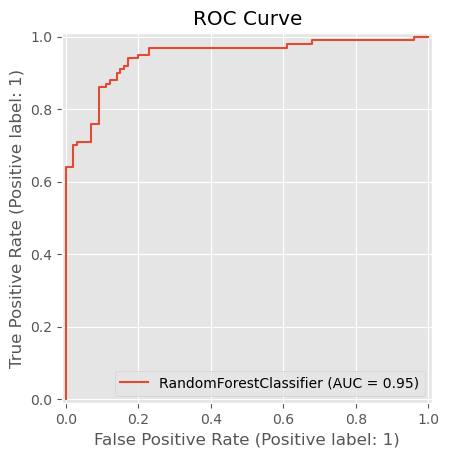

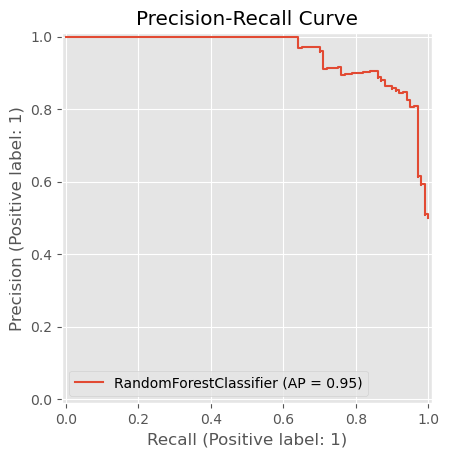

############################################## 
Classification Report for df3
############################################## 

Matriz de confusión: 



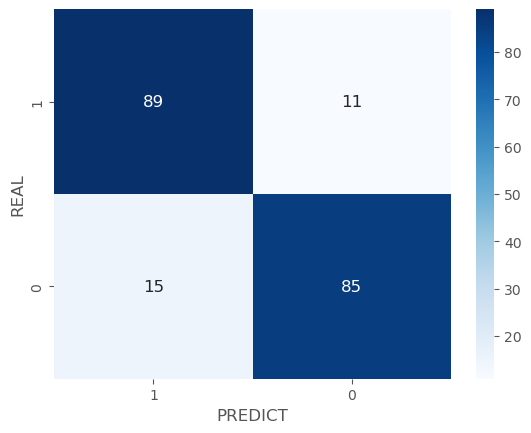

Accuracy:  0.87
Precision: 0.885
Recall:    0.85
Fscore:    0.867




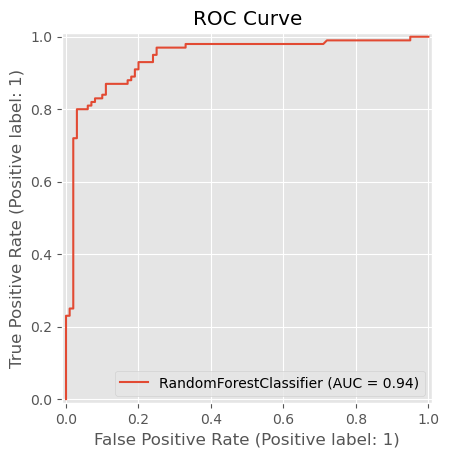

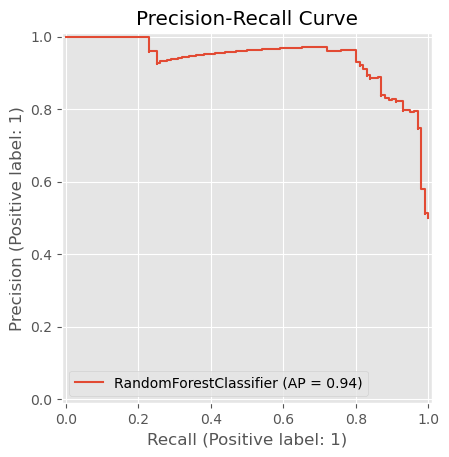

In [37]:
for rf, df_test, name in zip(rf_models, datasets_test, datasets_names):

    print('############################################## ')
    print('Classification Report for ' + name)
    print('############################################## \n')

    X_test = df_test[['X1', 'X2']].to_numpy()
    y_test = df_test['y'].to_numpy()

    df_test['y_rf'] = rf.predict(X_test)

    # Matriz de confusión
    print('Matriz de confusión: \n')
    conf_mat = confusion_matrix(y_test, df_test['y_rf'])
    sns.heatmap(conf_mat, annot=True, xticklabels=[1, 0], yticklabels=[1, 0],
                cmap='Blues', annot_kws={"fontsize":12})
    plt.xlabel('PREDICT')
    plt.ylabel('REAL')
    plt.show()

    # Métricas
    print("Accuracy: ", accuracy_score(y_test, df_test['y_rf']))
    print('Precision:', round(precision_score(y_test, df_test['y_rf']), 3))
    print('Recall:   ', round(recall_score(y_test, df_test['y_rf']), 3))
    print('Fscore:   ', round(f1_score(y_test, df_test['y_rf']), 3))
    print('\n')

    # Curva ROC
    RocCurveDisplay.from_estimator(rf, X_test, y_test)
    plt.title('ROC Curve')
    plt.show()

    # Curva Precision-Recall
    PrecisionRecallDisplay.from_estimator(rf, X_test, y_test)
    plt.title('Precision-Recall Curve')
    plt.show()

# GRADIENT BOOSTING

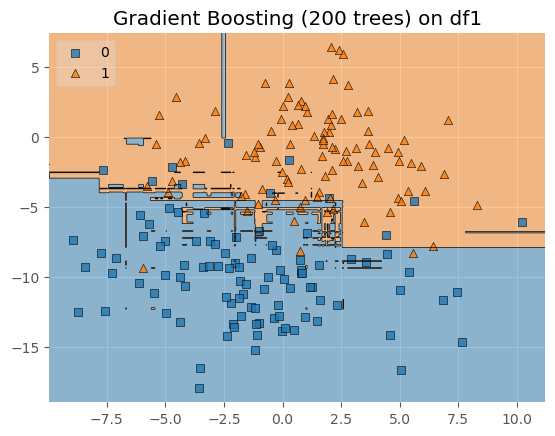

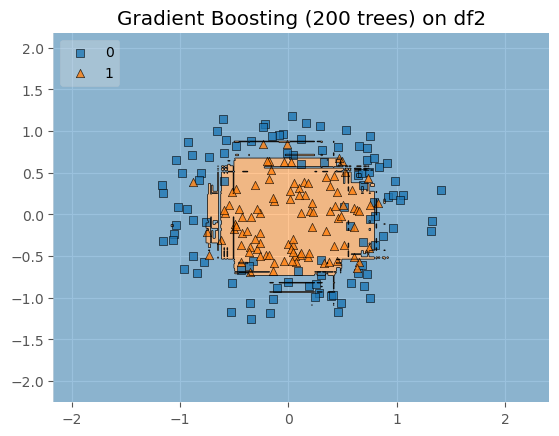

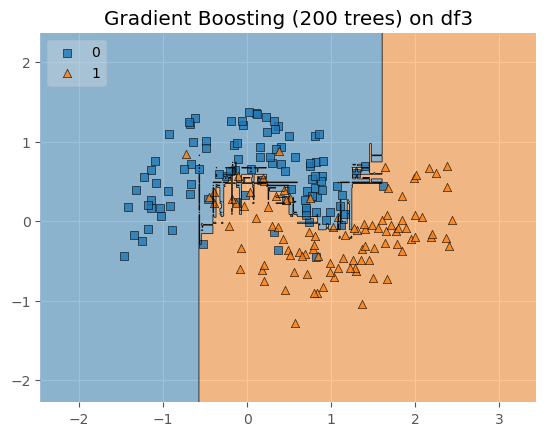

In [38]:
from sklearn.ensemble import GradientBoostingClassifier
import matplotlib.pyplot as plt

gb_models = []

for df_train, df_test, name in zip(datasets_train, datasets_test, datasets_names):

    X_train = df_train[['X1', 'X2']].to_numpy()
    y_train = df_train['y'].to_numpy()

    X_test  = df_test[['X1', 'X2']].to_numpy()
    y_test  = df_test['y'].to_numpy()

    gb = GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=3,          # profundidad de cada árbol (stumps/árboles pequeños)
        random_state=42
    )
    gb.fit(X_train, y_train)

    plot_decision_regions(X_test, y_test, clf=gb, legend=2)
    plt.title('Gradient Boosting (200 trees) on ' + name)
    plt.show()

    gb_models.append(gb)

############################################## 
Classification Report for df1
############################################## 

Matriz de confusión: 



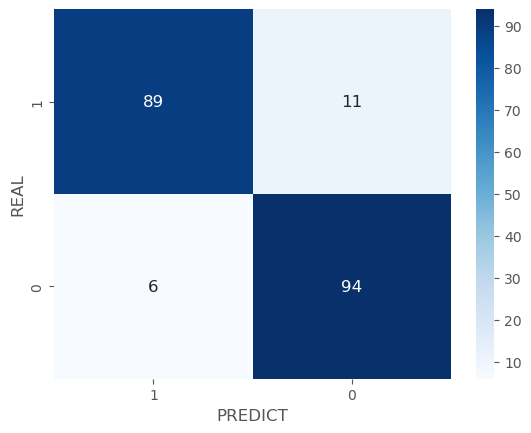

Accuracy:  0.915
Precision: 0.895
Recall:    0.94
Fscore:    0.917




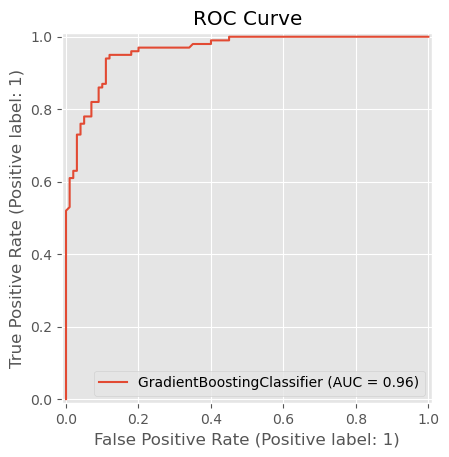

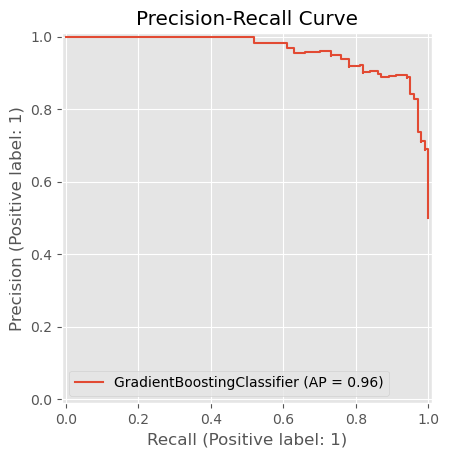

############################################## 
Classification Report for df2
############################################## 

Matriz de confusión: 



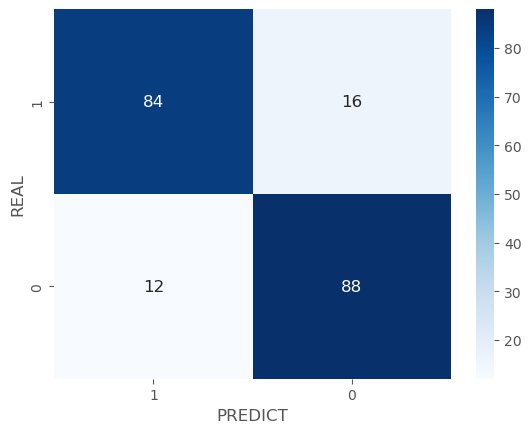

Accuracy:  0.86
Precision: 0.846
Recall:    0.88
Fscore:    0.863




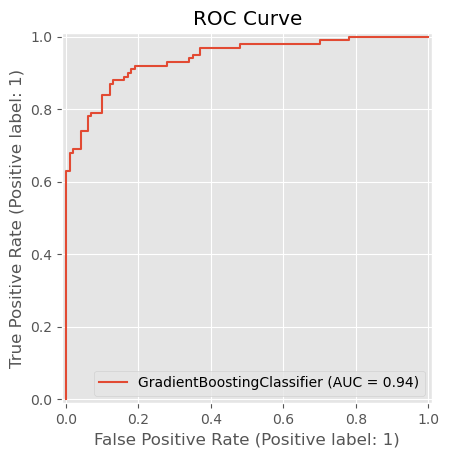

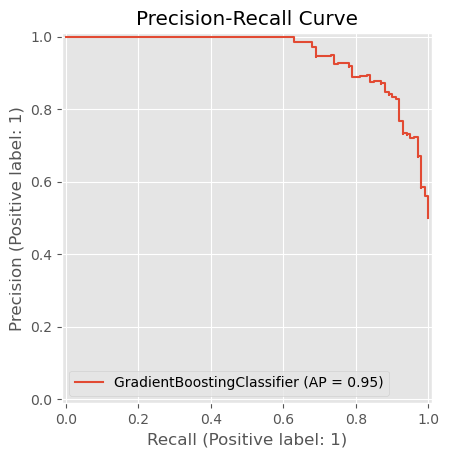

############################################## 
Classification Report for df3
############################################## 

Matriz de confusión: 



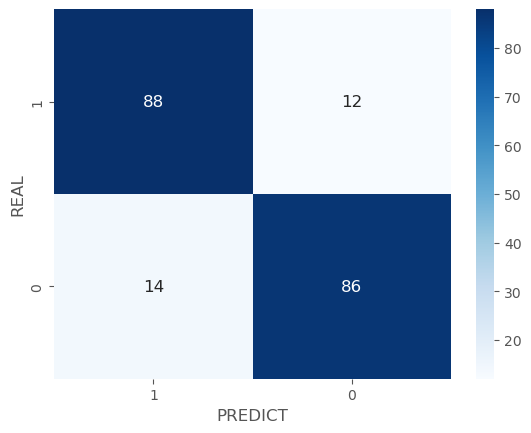

Accuracy:  0.87
Precision: 0.878
Recall:    0.86
Fscore:    0.869




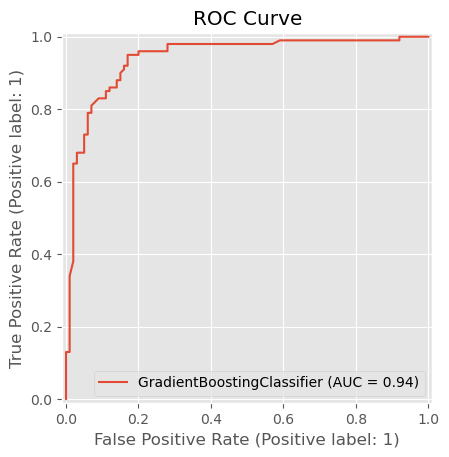

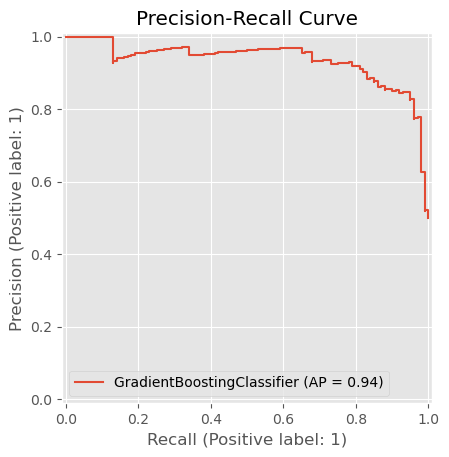

In [39]:
for gb, df_test, name in zip(gb_models, datasets_test, datasets_names):

    print('############################################## ')
    print('Classification Report for ' + name)
    print('############################################## \n')

    X_test = df_test[['X1', 'X2']].to_numpy()
    y_test = df_test['y'].to_numpy()

    df_test['y_gb'] = gb.predict(X_test)

    # Matriz de confusión
    print('Matriz de confusión: \n')
    conf_mat = confusion_matrix(y_test, df_test['y_gb'])
    sns.heatmap(conf_mat, annot=True, xticklabels=[1, 0], yticklabels=[1, 0],
                cmap='Blues', annot_kws={"fontsize":12})
    plt.xlabel('PREDICT')
    plt.ylabel('REAL')
    plt.show()

    # Métricas
    print("Accuracy: ", accuracy_score(y_test, df_test['y_gb']))
    print('Precision:', round(precision_score(y_test, df_test['y_gb']), 3))
    print('Recall:   ', round(recall_score(y_test, df_test['y_gb']), 3))
    print('Fscore:   ', round(f1_score(y_test, df_test['y_gb']), 3))
    print('\n')

    # Curva ROC
    RocCurveDisplay.from_estimator(gb, X_test, y_test)
    plt.title('ROC Curve')
    plt.show()

    # Curva Precision-Recall
    PrecisionRecallDisplay.from_estimator(gb, X_test, y_test)
    plt.title('Precision-Recall Curve')
    plt.show()

El rendimiento de los algoritmos depende de la estructura del conjunto de datos. En el dataset linealmente separable, los modelos lineales, especialmente SVM con kernel lineal, obtienen el mejor desempeño, ya que la frontera óptima es un hiperplano y no se requiere mayor complejidad.

En los datasets no lineales, como los de tipo “moons” o “circles”, los modelos lineales presentan underfitting al no poder capturar fronteras curvas. En estos casos, SVM con kernel RBF, KNN y los métodos de ensamble (Random Forest y Gradient Boosting) muestran un rendimiento superior debido a su mayor capacidad de modelar relaciones no lineales.

Los árboles individuales tienden a sobreajustar si no se regulan, mientras que los métodos de ensamble ofrecen un comportamiento más robusto al reducir la varianza. En conclusión, no existe un modelo universalmente mejor, sino que el rendimiento depende del equilibrio entre la complejidad del modelo y la estructura del problema.